# 01 · A · Le strict minimum

*Module 14 « Feature engineering & transformation » · TD du mercredi 21 octobre 2026 · environ 20 minutes en salle.*

### Ce qu'on fait

On ne crée **aucune variable**. Les 25 colonnes brutes retenues au notebook 00 entrent telles quelles, avec la
seule préparation dont un modèle a besoin pour calculer : boucher les trous, mettre les nombres à la même
échelle, transformer les étiquettes en colonnes de 0 et de 1. Les cinq modèles du TD reçoivent exactement la même
préparation : c'est la référence que les approches B, C et D devront battre.

### Les choix de cette approche

| Décision | Choix | Pourquoi |
|---|---|---|
| Variables | les 14 numériques et les 11 catégorielles brutes autorisées (`NUMERIQUES`, `CATEGORIELLES`) ; aucune variable créée | mesurer ce que valent les données « telles quelles », avant d'y mettre du métier |
| Manquants des numériques | `SimpleImputer(strategy="median")` | seules quatre valeurs de `children` manquent ; la médiane ne se laisse pas tirer par les valeurs extrêmes |
| Échelle des numériques | `StandardScaler()` | `lead_time` monte à 737 jours, `is_repeated_guest` vaut 0 ou 1 : sans mise à l'échelle, distances et pénalités ne voient que les grandes unités |
| `agent`, `company`, `country` | traitées comme des **catégorielles** | ce sont des étiquettes : l'agent 240 n'est pas « plus grand » que l'agent 9 |
| Encodage des catégorielles | `OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False)` | une colonne par modalité ; les modalités vues moins de 20 fois au train partagent une colonne « autres », où vont aussi celles jamais vues (une variable sans modalité rare code une inconnue par des zéros) |
| Manquants des catégorielles | gardés comme une modalité à part (`agent_nan`…) | l'absence d'agent est une information ; le one-hot de scikit-learn la code sans qu'on le lui demande |
| Assemblage | un `ColumnTransformer` placé dans un `Pipeline`, ajusté sur le train seul | fit sur le train, transform partout |
| Modèles | les cinq de `fe_tp.evaluation.modeles()`, réglages fixes | seule la préparation change d'une approche à l'autre |

### Les outils utilisés

- `pandas` : `dtypes`, `nunique`, `isna` pour classer les colonnes (cours 1, slide 6) ; `pd.get_dummies`, pour
  voir son piège (cours 1, slide 20).
- `SimpleImputer` et `StandardScaler` : la médiane, la moyenne et l'écart-type sont appris sur le train
  (cours 1, slide 7 ; cours 2, slides 3 et 5).
- `OneHotEncoder` avec `min_frequency` et `handle_unknown="infrequent_if_exist"` (cours 1, slides 20 et 21).
- `ColumnTransformer`, `make_pipeline`, `get_feature_names_out` (cours 2, slide 24).
- `pairwise_distances`, pour mesurer le fléau de la dimension (cours 2, slide 11).
- Le paquet du TD : `fe_tp.donnees.charger` et `decouper`, `fe_tp.evaluation.evaluer` et `modeles`.

### Ce qu'on regarde à la fin

Le tableau des cinq modèles (AUC ROC, précision moyenne, exactitude, nombre de colonnes, durée) et le diagramme
des AUC : quel score obtient-on sans aucune idée métier, et quels modèles souffrent d'une préparation unique ?

## 1. Charger et découper

Comme au notebook 00 : `charger()` lit le fichier et retire les 182 lignes impossibles, `decouper()` coupe dans
le temps (le modèle est mis en service le 22 avril 2017). On ne garde que les colonnes autorisées.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import pairwise_distances, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from fe_tp.donnees import CATEGORIELLES, CIBLE, NUMERIQUES, charger, decouper
from fe_tp.evaluation import evaluer, modeles

In [2]:
df = charger()
train, test = decouper(df)
X_train, y_train = train[NUMERIQUES + CATEGORIELLES], train[CIBLE]
X_test, y_test = test[NUMERIQUES + CATEGORIELLES], test[CIBLE]
pd.DataFrame({"réservations": [len(X_train), len(X_test)], "colonnes": [X_train.shape[1], X_test.shape[1]],
              "taux d'annulation": [y_train.mean(), y_test.mean()]}, index=["train", "test"]).round(3)

,réservations,colonnes,taux d'annulation
train,95190,25,0.361
test,24018,25,0.410


Le train compte 95 190 réservations, le test 24 018, avec les mêmes 25 colonnes. Le test annule davantage
(41,0 % contre 36,1 %) : un modèle qui répondrait toujours « non annulée » y aurait déjà une exactitude de 59 %,
à garder en tête pour lire l'exactitude plus bas.

## 2. Classer avant de transformer

Avant de choisir une transformation, on classe les colonnes (cours 1, slide 6). D'abord les 14 numériques :
leur type, le nombre de valeurs distinctes, les manquants et l'étendue, sur le train.

In [3]:
num = X_train[NUMERIQUES]
pd.DataFrame({"type": num.dtypes.astype(str), "valeurs distinctes": num.nunique(),
              "manquants": num.isna().sum(), "min": num.min(), "max": num.max()})

,type,valeurs distinctes,manquants,min,max
lead_time,int64,452,0,0.0,737.0
arrival_date_week_number,int64,53,0,1.0,53.0
arrival_date_day_of_month,int64,31,0,1.0,31.0
stays_in_weekend_nights,int64,17,0,0.0,19.0
stays_in_week_nights,int64,33,0,0.0,50.0
adults,int64,14,0,0.0,55.0
children,float64,5,4,0.0,10.0
babies,int64,5,0,0.0,10.0
is_repeated_guest,int64,2,0,0.0,1.0
previous_cancellations,int64,15,0,0.0,26.0


Seule `children` a des manquants (4 sur 95 190) : la médiane suffit. Les étendues n'ont rien à voir entre elles :
de 0 à 1 pour `is_repeated_guest`, de 0 à 508 pour `adr`, de 0 à 737 pour `lead_time`. Remarquez aussi que
`arrival_date_week_number` est une date déguisée en nombre : la semaine 53 est voisine de la semaine 1, ce que
l'approche A ignore. L'approche B la remplacera par le mois d'arrivée, codé en cycle (un sinus et un cosinus).

Puis les 11 catégorielles :

In [4]:
cat = X_train[CATEGORIELLES]
pd.DataFrame({"type": cat.dtypes.astype(str), "modalités": cat.nunique(), "manquants": cat.isna().sum(),
              "la plus fréquente": cat.mode().iloc[0]})

,type,modalités,manquants,la plus fréquente
hotel,object,2,0,City Hotel
arrival_date_month,object,12,0,October
meal,object,5,0,BB
country,object,165,473,PRT
market_segment,object,8,0,Online TA
distribution_channel,object,5,0,TA/TO
reserved_room_type,object,9,0,A
deposit_type,object,3,0,No Deposit
customer_type,object,4,0,Transient
agent,object,311,13730,9


Trois colonnes ont beaucoup de modalités : `country` (165), `agent` (311) et `company` (328). `company` manque
dans 89 290 réservations sur 95 190 (94 %), `agent` dans 13 730 (14 %). L'agent le plus fréquent est le « 9 » :
un numéro, mais une étiquette. `charger()` lit donc `agent` et `company` comme du texte (`object`).

> 💬 **Pour la salle.** Que se passerait-il si `agent` restait une colonne numérique, standardisée comme les autres ?
>
> *Piste : numéroter, c'est inventer un ordre (cours 1, slide 19). La régression logistique supposerait que le
> risque d'annulation monte ou descend régulièrement de l'agent 1 à l'agent 527 ; un arbre s'en accommoderait
> mieux, en coupant sur des seuils, mais il lui faudrait beaucoup de coupures pour isoler un agent.*

## 3. Le piège de `pd.get_dummies`

`pd.get_dummies` fabrique une colonne par modalité **présente dans le tableau qu'on lui donne**. Appliqué au
train puis au test, il ne fabrique pas les mêmes colonnes (cours 1, slide 20).

In [5]:
pays_train = pd.get_dummies(X_train[["country"]])
pays_test = pd.get_dummies(X_test[["country"]])
pays_train.shape[1], pays_test.shape[1]

(165, 136)

165 colonnes au train, 136 au test : un modèle appris sur les premières ne sait pas lire les secondes. Et même à
nombre égal, rien ne garantirait que la 40ᵉ colonne désigne le même pays des deux côtés. D'où vient l'écart ?

In [6]:
inconnus = sorted(set(X_test["country"].dropna()) - set(X_train["country"].dropna()))
absents_du_test = set(X_train["country"].dropna()) - set(X_test["country"].dropna())
print(len(inconnus), "pays du test jamais vus au train :", inconnus)
print("réservations du test concernées :", X_test["country"].isin(inconnus).sum())
print("pays du train absents du test :", len(absents_du_test))

12 pays du test jamais vus au train : ['ATF', 'BHS', 'DJI', 'FJI', 'FRO', 'KIR', 'LAO', 'MYT', 'NCL', 'SDN', 'SLE', 'UMI']
réservations du test concernées : 18
pays du train absents du test : 41


Les deux sens jouent : 41 pays du train ne réapparaissent pas au test, et 12 pays du test (18 réservations)
n'ont jamais été vus au train. C'est la ville inconnue qui arrive en production (cours 1, slide 21).

`OneHotEncoder` apprend la liste des modalités **sur le train** (`fit`) et la réapplique partout (`transform`).
Avec `min_frequency=20`, les pays vus moins de 20 fois au train sont regroupés dans une colonne « autres »,
`country_infrequent_sklearn` ; avec `handle_unknown="infrequent_if_exist"`, les pays jamais vus y vont aussi.

In [7]:
ohe_pays = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False)
ohe_pays.fit(X_train[["country"]])
codes_test = pd.DataFrame(ohe_pays.transform(X_test[["country"]]), columns=ohe_pays.get_feature_names_out())
pays_inconnus = X_test["country"].isin(inconnus).to_numpy()
pd.Series({"colonnes en sortie, au train comme au test": codes_test.shape[1],
           "pays rares au train (moins de 20 réservations)": len(ohe_pays.infrequent_categories_[0]),
           "réservations du test aux pays inconnus": pays_inconnus.sum(),
           "… rangées dans country_infrequent_sklearn": codes_test.loc[pays_inconnus, "country_infrequent_sklearn"].sum()
           }).astype(int)

colonnes en sortie, au train comme au test        72
pays rares au train (moins de 20 réservations)    95
réservations du test aux pays inconnus            18
… rangées dans country_infrequent_sklearn         18
dtype: int64

72 colonnes au train comme au test : 70 pays fréquents, une colonne pour le pays manquant (`country_nan`) et une
colonne « autres » pour les rares. Les 95 pays rares du train et les 18 réservations aux pays inconnus partagent
cette dernière : le modèle ne plante pas, il traite un pays nouveau comme un pays rare.

## 4. La préparation : un `ColumnTransformer`

Chaque groupe de colonnes reçoit sa préparation, et l'ensemble devient un seul objet (cours 2, slide 24) :
médiane puis standardisation pour les numériques, one-hot pour les catégorielles. On l'ajuste ici sur le train
pour l'inspecter ; `evaluer` le réajustera de lui-même, dans chaque pipeline.

In [8]:
numerique = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
one_hot = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False)
prep = ColumnTransformer([("num", numerique, NUMERIQUES), ("cat", one_hot, CATEGORIELLES)],
                         verbose_feature_names_out=False)
prep.fit(X_train)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The

Le schéma (cliquable dans Jupyter) montre deux branches parallèles : `num` (médiane, puis standardisation) pour
les 14 numériques et `cat` (one-hot) pour les 11 catégorielles ; leurs sorties sont posées côte à côte. Combien
de colonnes chaque catégorielle produit-elle ?

In [9]:
noms = pd.Series(prep.get_feature_names_out())
encodeur = prep.named_transformers_["cat"]
pd.DataFrame({"modalités au train (manquant compris)": [len(c) for c in encodeur.categories_],
              "rares (moins de 20 fois)": [0 if r is None else len(r) for r in encodeur.infrequent_categories_],
              "colonnes one-hot": [noms.str.startswith(f"{c}_").sum() for c in CATEGORIELLES]},
             index=CATEGORIELLES)

,modalités au train (manquant compris),rares (moins de 20 fois),colonnes one-hot
hotel,2,0,2
arrival_date_month,12,0,12
meal,5,0,5
country,166,95,72
market_segment,8,1,8
distribution_channel,5,1,5
reserved_room_type,9,1,9
deposit_type,3,0,3
customer_type,4,0,4
agent,312,142,171


In [10]:
print(len(noms), "colonnes en sortie :", noms.isin(NUMERIQUES).sum(), "numériques et",
      (~noms.isin(NUMERIQUES)).sum(), "colonnes one-hot")

365 colonnes en sortie : 14 numériques et 351 colonnes one-hot


La préparation sort 365 colonnes : 14 numériques et 351 colonnes de 0 et de 1. `agent` en fournit à lui seul
171 (ses 312 modalités, dont 142 rares regroupées en une), `country` 72 et `company` 60 : sans `min_frequency`, ces
trois colonnes en auraient produit 807. Voici les colonnes « autres » et les colonnes de manquants :

In [11]:
noms[noms.str.contains("infrequent|_nan")].tolist()

['country_nan',
 'country_infrequent_sklearn',
 'market_segment_infrequent_sklearn',
 'distribution_channel_infrequent_sklearn',
 'reserved_room_type_infrequent_sklearn',
 'agent_nan',
 'agent_infrequent_sklearn',
 'company_nan',
 'company_infrequent_sklearn']

Six colonnes « autres » et trois colonnes de manquants. `agent_nan` vaut 1 quand la réservation passe sans agent :
c'est l'indicateur de manquant du cours 1 (slide 18), fabriqué ici sans qu'on le demande. Est-il utile ?

In [12]:
y_train.groupby(X_train["agent"].isna().rename("agent manquant")).mean().round(3)

agent manquant
False    0.385
True     0.216
Name: is_canceled, dtype: float64

Au train, les réservations sans agent annulent à 21,6 %, contre 38,5 % pour celles qui passent par un agent :
l'absence est une information, et le one-hot la transmet au modèle.

Reste la branche numérique. Ce qu'elle a appris tient en trois vecteurs, calculés sur le train : la médiane de
chaque colonne (pour boucher les trous), puis sa moyenne et son écart-type (cours 1, slide 7). Appliquons-la au
test, sans rien réapprendre, et regardons les deux derniers.

In [13]:
branche = prep.named_transformers_["num"]
test_standardise = branche.transform(X_test[NUMERIQUES])
pd.DataFrame({"moyenne apprise": branche[-1].mean_, "écart-type appris": branche[-1].scale_,
              "moyenne au test, après": test_standardise.mean(axis=0),
              "écart-type au test, après": test_standardise.std(axis=0)},
             index=NUMERIQUES).round(2)

,moyenne apprise,écart-type appris,"moyenne au test, après","écart-type au test, après"
lead_time,96.36,104.49,0.37,1.06
arrival_date_week_number,27.65,14.94,-0.16,0.36
arrival_date_day_of_month,15.63,8.71,0.10,1.04
stays_in_weekend_nights,0.90,1.00,0.13,0.99
stays_in_week_nights,2.45,1.91,0.12,0.97
adults,1.84,0.60,0.14,0.79
children,0.09,0.38,0.15,1.25
babies,0.01,0.10,-0.01,0.83
is_repeated_guest,0.03,0.18,-0.04,0.88
previous_cancellations,0.11,0.94,-0.10,0.21


Au train, chaque colonne standardisée a, par construction, une moyenne de 0 et un écart-type de 1. Au test, non :
`lead_time` y vaut en moyenne 0,37 écart-type de plus qu'au train, et `adr` 0,95. Deux effets s'additionnent.
La saison d'abord : les arrivées d'avril à août se réservent plus tôt et se paient plus cher. L'année ensuite :
le test tombe en 2017, alors que le train mélange 2015, 2016 et le début de 2017, et les prix comme les délais
montent d'une année sur l'autre. Les écarts-types bougent aussi :
`arrival_date_week_number` n'a plus que 0,36, car le test ne couvre que les semaines d'avril à août. C'est voulu :
fit sur le train, transform partout. Le test est lu avec les paramètres du train, comme le seront les réservations
de production.

> 💬 **Pour la salle.** Faut-il aussi standardiser les 351 colonnes one-hot ?
>
> *Piste : en général, non. Elles sont déjà sur une échelle commune (0 ou 1) et se lisent bien (« la modalité
> est présente »). Standardisée, une modalité rare de fréquence p prendrait la valeur d'environ 1/√p : elle
> pèserait très lourd dans les distances du kNN. Ici, on ne le fait pas.*

## 5. Évaluer les cinq modèles

`evaluer` construit, pour chacun des cinq modèles, `Pipeline([("prep", clone(prep)), ("modele", modele)])`,
l'ajuste sur le train et le mesure sur le test. Il écrit aussi `output/resultats_A.csv` et
`output/probas_A.parquet`, que le notebook 05 relira. Comptez quelques minutes.

In [14]:
resultats, pipelines = evaluer("A · strict minimum", prep, X_train, y_train, X_test, y_test)
resultats.drop(columns="approche")

,modele,famille,auc,precision_moyenne,exactitude,nb_variables,duree_s
0,Régression logistique,linéaire,0.853,0.820,0.764,365,10.446
1,kNN,distances,0.817,0.782,0.749,365,19.875
2,Réseau de neurones,réseau,0.854,0.820,0.766,365,49.198
3,Forêt aléatoire,arbres,0.870,0.828,0.757,365,16.988
4,Gradient boosting,arbres,0.873,0.834,0.778,365,12.162


Les deux modèles à arbres arrivent en tête : AUC de 0,873 pour le gradient boosting, 0,870 pour la forêt. Le
réseau (0,854) et la régression logistique (0,853) suivent de près ; le kNN ferme la marche (0,817). La précision
moyenne range les modèles dans le même ordre (de 0,782 à 0,834 ; le réseau et la régression logistique y sont à
égalité, 0,820). L'exactitude au seuil 0,5, elle, va de 74,9 % à 77,8 %, contre 59 % pour la réponse constante
« non annulée » ; elle dépend du seuil, et la forêt, deuxième en AUC, n'y est que quatrième (75,7 %).

Côté coût (colonne `duree_s`, entraînement et prédiction, sur la machine qui a exécuté ce notebook) : le
boosting est le plus rapide (8,5 s), le réseau le plus lent (38 s). Le kNN, lui, se contente de mémoriser le
train : ses 32 s passent à chercher les 50 voisins de chacune des 24 018 réservations du test parmi les 95 190 du
train. Ces durées varient d'une exécution à l'autre ; leur ordre de grandeur, non.

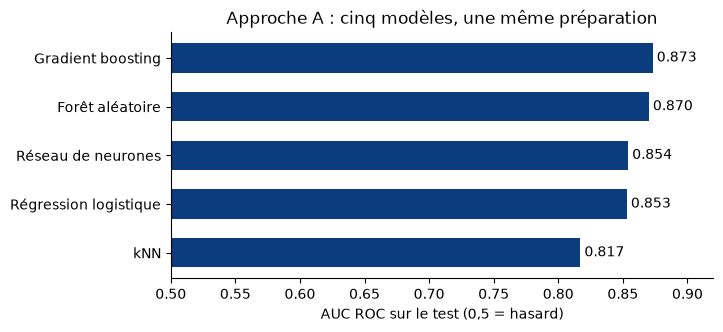

In [15]:
ordre = resultats.sort_values("auc")
fig, ax = plt.subplots(figsize=(7, 3.2))
barres = ax.barh(ordre["modele"], ordre["auc"], color="#0B3C7D", height=0.6)
ax.bar_label(barres, fmt="%.3f", padding=3)
ax.set_xlim(0.5, 0.92)
ax.set_xlabel("AUC ROC sur le test (0,5 = hasard)")
ax.set_title("Approche A : cinq modèles, une même préparation")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

L'écart entre le premier et le dernier modèle (0,873 contre 0,817) est près de trois fois plus grand que celui
qui sépare les quatre premiers (de 0,853 à 0,873). Sans créer une seule variable, on atteint déjà une AUC
d'environ 0,87 : c'est le score que les approches B, C et D devront battre.

## 6. Lire les résultats

### 6.1 Ce que la régression logistique a appris

Chaque colonne reçoit un coefficient : positif, il pousse vers l'annulation ; négatif, il la retient. Voici les
cinq plus forts de chaque côté. Attention à l'unité : pour une numérique, le coefficient vaut pour un écart-type
de plus ; pour une colonne one-hot, pour la présence de la modalité.

In [16]:
logistique = pipelines["Régression logistique"]
coefficients = pd.Series(logistique["modele"].coef_[0], index=logistique["prep"].get_feature_names_out())
coefficients = coefficients.sort_values()
pd.concat([coefficients.head(5), coefficients.tail(5)]).round(2).to_frame("coefficient")

,coefficient
company_233,-2.86
agent_152,-2.06
deposit_type_No Deposit,-1.83
company_72,-1.77
agent_308,-1.69
country_ARE,2.03
company_498,2.04
agent_17,2.42
agent_281,2.44
deposit_type_Non Refund,2.63


Ce sont les cinq coefficients les plus négatifs et les cinq plus positifs, pas les dix plus grands en valeur
absolue. Sept portent sur un agent ou une société (`agent_281`, `agent_17`, `company_233`…), deux sur le type de
dépôt (`Non Refund` à +2,63, `No Deposit` à −1,83), un sur un pays (`country_ARE`, les Émirats arabes unis). Avec
une colonne par agent, la régression logistique peut apprendre le risque propre à chacun. Mais un gros coefficient
ne fait pas une variable importante : il donne l'effet de la modalité quand elle est présente, pas le nombre de
réservations qui la portent. Pour savoir ce que les agents apportent au score, il faudrait retirer leurs colonnes,
réentraîner et comparer l'AUC.

### 6.2 Le kNN et le fléau de la dimension

Le kNN classe une réservation d'après ses 50 plus proches voisins du train, au sens de la distance euclidienne
sur les 365 colonnes. La slide 11 du cours 2 prévient : en grande dimension, les voisins s'éloignent et toutes
les distances se ressemblent. Mesurons-le sur 300 réservations du test et 2 000 du train, d'abord dans l'espace
des 14 numériques, puis dans les 365 colonnes.

In [17]:
voisins = prep.transform(X_train.sample(2000, random_state=0))
requetes = prep.transform(X_test.sample(300, random_state=0))
distances = {}
for espace, colonnes in [("14 numériques", slice(0, 14)), ("365 colonnes", slice(None))]:
    d = np.sort(pairwise_distances(requetes[:, colonnes], voisins[:, colonnes]), axis=1)
    distances[espace] = {"plus proche": np.median(d[:, 0]), "50ᵉ voisin": np.median(d[:, 49]),
                         "plus lointain": np.median(d[:, -1]),
                         "écart relatif": np.median((d[:, -1] - d[:, 0]) / d[:, 0])}
pd.DataFrame(distances).T.round(2)

,plus proche,50ᵉ voisin,plus lointain,écart relatif
14 numériques,1.15,2.24,26.90,22.45
365 colonnes,2.55,3.70,27.19,9.63


Dans les 14 numériques, le plus proche voisin est en médiane à 1,15, le plus lointain à 26,9 : un écart
relatif de 22,45. Dans les 365 colonnes, le plus proche s'éloigne (2,55), le 50ᵉ aussi (de 2,24 à 3,70), alors
que le plus lointain ne bouge presque pas (27,19) : l'écart relatif tombe à 9,63. Les distances se ressemblent
davantage : le plus proche voisin se distingue moins du plus lointain. C'est le fléau de la dimension de la
slide 11 du cours 2, sur nos données. Le mécanisme est simple :
deux réservations passées par deux agents différents ajoutent 2 au carré de leur distance, autant qu'un écart de
√2 ≈ 1,4 écart-type sur `lead_time`, soit environ 148 jours de délai (σ = 104,49 jours, voir le tableau de la
section 4).

Faut-il alors retirer les colonnes one-hot ? Essayons le même kNN (mêmes réglages) sur les 14 numériques seules.

In [18]:
knn_numeriques = make_pipeline(ColumnTransformer([("num", numerique, NUMERIQUES)]), modeles()["kNN"])
knn_numeriques.fit(X_train, y_train)
round(roc_auc_score(y_test, knn_numeriques.predict_proba(X_test)[:, 1]), 3)

0.675

0,675 contre 0,817 avec les 365 colonnes : sans les catégorielles, le kNN perd 0,14 d'AUC. Le type de dépôt,
l'agent et le segment de marché portent de l'information. Le remède n'est donc pas de jeter l'information des
catégorielles, mais de la porter dans moins de colonnes, et de meilleures. C'est le pari de l'approche B
(variables métier, encodage par la cible) et de l'approche C (générer, puis réduire) ; le notebook 05 fera les
comptes.

### 6.3 Deux questions pour finir

> 💬 **Pour la salle.** La forêt et le boosting arrivent en tête, alors que la standardisation ne leur sert à
> rien. Pourquoi l'ignorent-ils ?
>
> *Piste : un arbre coupe sur des seuils (« `lead_time` < 120 ? »). Standardiser change les valeurs, pas leur
> ordre, donc pas les coupures possibles : seul l'ordre compte. Le notebook 04 le vérifie.*

> 💬 **Pour la salle.** Pourquoi `min_frequency=20`, plutôt que 1 ou 500 ?
>
> *Piste : une modalité vue trois fois donne une colonne presque vide et un coefficient mal estimé ; trop haut,
> on noie des agents utiles dans « autres ». C'est un réglage de la préparation, qu'on pourrait choisir par
> validation croisée (`GridSearchCV` sur `prep__cat__min_frequency`, cours 2, slide 24), avec des plis pris dans
> le temps (`TimeSeriesSplit`, comme au notebook 03) : les plis par défaut apprendraient en partie sur l'avenir.*

## À retenir

- **Sans créer une seule variable**, une préparation minimale (médiane, standardisation, one-hot) mène le
  gradient boosting à une AUC de 0,873 et la forêt à 0,870 : c'est la référence des approches B, C et D.
- **`OneHotEncoder`, pas `pd.get_dummies`** : il mémorise les modalités du train (165 pays au train, 136 au test
  avec `get_dummies`, 72 colonnes des deux côtés avec `OneHotEncoder`). `min_frequency=20` et
  `handle_unknown="infrequent_if_exist"` rangent les rares et les inconnues dans une même colonne « autres » ; les
  manquants deviennent une modalité (`agent_nan`), et l'absence d'agent est une information.
- **Fit sur le train, transform partout** : médianes, moyennes, écarts-types et modalités viennent du train ; le
  test garde son propre décalage (`adr` à +0,95 écart-type), et c'est voulu.
- **Le one-hot fait gonfler la dimension** : 25 colonnes deviennent 365, dont 171 pour les seuls agents. La
  régression logistique donne ses plus forts coefficients à des agents et à des sociétés, mais un fort coefficient
  ne mesure pas ce qu'une colonne apporte au score. Le kNN souffre de la dimension (les distances se resserrent),
  mais il fait bien pire sans les catégorielles (0,675).
- **Une même préparation pour cinq modèles est un point de départ, pas un optimum** : chaque famille a ses besoins
  (fiche réflexe, cours 2, slide 28). Les notebooks 02 à 05 le mesurent.